# Red Neuronal Perceptrón Multicapa (MLP) FROM SCRATCH
Luis Angel Flores Espinosa

Deep Learning

In [13]:
import numpy as np  # Importa NumPy: base de todo el cálculo de la red (matrices, operaciones vectorizadas)
import pandas as pd  # Importa pandas solo para cargar y describir el dataset
import matplotlib.pyplot as plt  # Importa matplotlib para graficar

## 1. Selección de los patrones para entrenamiento (Dataset)

### 1.1 Descripción del dataset
**Iris** contiene **150 muestras** de flores de 3 especies (*Iris-setosa*, *Iris-versicolor*, *Iris-virginica*), 50 por especie. Cada muestra tiene 4 atributos en cm: `sepal-length`, `sepal-width`, `petal-length` y `petal-width`. El CSV no trae encabezados, por eso se asignan los nombres al cargarlo.

In [14]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/iris.csv"  # URL del archivo CSV del dataset
columnas = ["sepal-length", "sepal-width", "petal-length", "petal-width", "class"]  # Nombres de las 5 columnas
df = pd.read_csv(url, header=None, names=columnas)  # Carga el CSV (sin encabezado) en un DataFrame
print("Dimensiones:", df.shape)  # Muestra (filas, columnas)
print(df["class"].value_counts())  # Cuenta las muestras de cada clase
df.head()  # Muestra las primeras 5 filas

Dimensiones: (150, 5)
class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,sepal-length,sepal-width,petal-length,petal-width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [15]:
df.describe()  # Estadísticos descriptivos (media, desv. est., mín, máx, cuartiles) de cada atributo

,sepal-length,sepal-width,petal-length,petal-width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### 1.2 Scatter plot

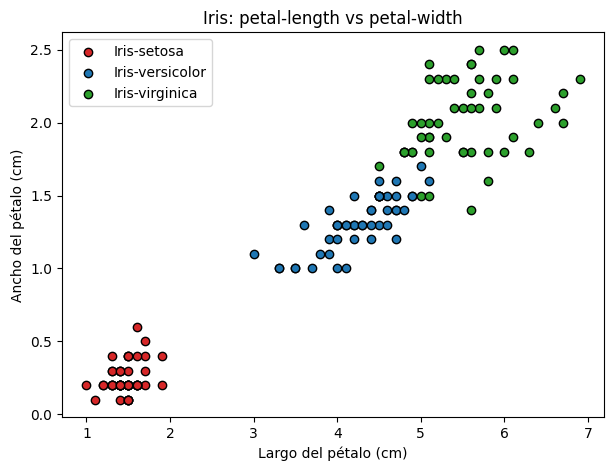

In [16]:
plt.figure(figsize=(7, 5))  # Crea una figura de 7x5 pulgadas
colores = {"Iris-setosa": "tab:red", "Iris-versicolor": "tab:blue", "Iris-virginica": "tab:green"}  # Color de cada especie
for especie, color in colores.items():  # Recorre cada especie con su color
    sub = df[df["class"] == especie]  # Filtra las filas de la especie actual
    plt.scatter(sub["petal-length"], sub["petal-width"], c=color, edgecolor="k", label=especie)  # Dibuja sus puntos (X: largo, Y: ancho del pétalo)
plt.xlabel("Largo del pétalo (cm)")  # Etiqueta del eje X
plt.ylabel("Ancho del pétalo (cm)")  # Etiqueta del eje Y
plt.title("Iris: petal-length vs petal-width")  # Título del gráfico
plt.legend()  # Muestra la leyenda con las especies
plt.show()  # Muestra el gráfico

*Setosa* se separa claramente de las otras dos; *versicolor* y *virginica* se solapan, por lo que se necesita una frontera de decisión no lineal.

## 2. Preprocesamiento del dataset

Primero se separan los atributos (`X`) de la clase (`y`). Las clases se codifican como enteros (0, 1, 2) y luego en **one-hot** (ej. clase 1 → `[0, 1, 0]`), que es el formato de la salida de la red.

In [17]:
X = df.drop(columns=["class"]).values  # X: matriz (150, 4) con los atributos
clases, y = np.unique(df["class"].values, return_inverse=True)  # clases: nombres únicos; y: cada etiqueta como entero 0, 1, 2
K = len(clases)  # Número de clases (3)
print("Clases:", clases)  # Muestra los nombres de las clases
print("Etiquetas (primeras 5):", y[:5])  # Muestra las primeras etiquetas codificadas

Clases: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Etiquetas (primeras 5): [0 0 0 0 0]


### 2.1 Splitting
Se divide en **entrenamiento (70 %)** y **prueba (30 %)**, de forma **estratificada** (misma proporción de clases en ambos conjuntos).

In [18]:
rng = np.random.default_rng(42)  # Generador aleatorio con semilla fija (reproducibilidad)
idx_train, idx_test = [], []  # Listas donde se guardarán los índices de cada conjunto
for k in range(K):  # Recorre cada clase para hacer la división estratificada
    idx_k = np.where(y == k)[0]  # Índices de las muestras de la clase k
    rng.shuffle(idx_k)  # Mezcla aleatoriamente esos índices
    n_tr = int(0.7 * len(idx_k))  # Cantidad de muestras de esa clase para entrenamiento (70 %)
    idx_train.extend(idx_k[:n_tr])  # Los primeros n_tr índices van a entrenamiento
    idx_test.extend(idx_k[n_tr:])  # El resto va a prueba
idx_train = rng.permutation(idx_train)  # Mezcla el orden de las muestras de entrenamiento
idx_test = np.array(idx_test)  # Convierte los índices de prueba a arreglo NumPy
X_train, y_train = X[idx_train], y[idx_train]  # Atributos y etiquetas de entrenamiento
X_test, y_test = X[idx_test], y[idx_test]  # Atributos y etiquetas de prueba
print("Entrenamiento:", X_train.shape[0], "muestras")  # Cantidad de muestras de entrenamiento
print("Prueba:", X_test.shape[0], "muestras")  # Cantidad de muestras de prueba

Entrenamiento: 105 muestras
Prueba: 45 muestras


### 2.2 Scaling
Se estandarizan los atributos (*z-score*): $x'=\frac{x-\mu}{\sigma}$. $\mu$ y $\sigma$ se calculan **solo con el conjunto de entrenamiento** (evita *data leakage*) y se aplican a ambos conjuntos.

In [19]:
mu = X_train.mean(axis=0)  # Media de cada atributo, calculada solo con entrenamiento
sigma = X_train.std(axis=0)  # Desviación estándar de cada atributo, solo con entrenamiento
X_train_s = (X_train - mu) / sigma  # Escala el conjunto de entrenamiento
X_test_s = (X_test - mu) / sigma  # Escala el conjunto de prueba con los mismos mu y sigma
print("Media entrenamiento escalado:", X_train_s.mean(axis=0).round(3))  # Verifica que las medias sean ≈ 0
print("Desv. est. entrenamiento escalado:", X_train_s.std(axis=0).round(3))  # Verifica que las desviaciones sean ≈ 1
Y_train = np.eye(K)[y_train]  # Codifica las etiquetas de entrenamiento en one-hot (matriz identidad indexada)
print("Y_train (primeras 3 filas):\n", Y_train[:3])  # Muestra ejemplo de la codificación one-hot

Media entrenamiento escalado: [ 0.  0. -0. -0.]
Desv. est. entrenamiento escalado: [1. 1. 1. 1.]
Y_train (primeras 3 filas):
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 0. 1.]]


## 3. Selección del modelo y entrenamiento

**Arquitectura:** 4 entradas → 10 neuronas (ReLU) → 10 neuronas (ReLU) → 3 salidas (softmax).

**Propagación hacia adelante** (cada fila de $A$ es una muestra):

$$Z^{(l)}=A^{(l-1)}W^{(l)}+\mathbf{b}^{(l)}\qquad A^{(l)}=f\left(Z^{(l)}\right)\qquad A^{(0)}=X$$

con $f=\text{ReLU}(z)=\max(0,z)$ en las capas ocultas y $\text{softmax}(z_k)=\frac{e^{z_k}}{\sum_j e^{z_j}}$ en la salida.

**Pérdida** (entropía cruzada): $J=-\frac{1}{N}\sum_{n}\sum_{k}y_k^{(n)}\ln\hat{y}_k^{(n)}$

**Backpropagation:**

$$\delta^{(L)}=\frac{\hat{Y}-Y}{N}\qquad \delta^{(l)}=\left(\delta^{(l+1)}{W^{(l+1)}}^{\top}\right)\odot f'\left(Z^{(l)}\right)$$

$$\frac{\partial J}{\partial W^{(l)}}={A^{(l-1)}}^{\top}\delta^{(l)}\qquad \frac{\partial J}{\partial \mathbf{b}^{(l)}}=\sum_n\delta^{(l)}_n$$

**Actualización** (descenso del gradiente, tasa $\eta$): $W^{(l)}\leftarrow W^{(l)}-\eta\,\frac{\partial J}{\partial W^{(l)}}$ , $\;\mathbf{b}^{(l)}\leftarrow \mathbf{b}^{(l)}-\eta\,\frac{\partial J}{\partial \mathbf{b}^{(l)}}$

In [20]:
class MLP:  # Define la clase de la red neuronal
    def __init__(self, capas, lr=0.1, seed=42):  # Constructor: capas = neuronas por capa, lr = tasa de aprendizaje
        rng = np.random.default_rng(seed)  # Generador aleatorio con semilla para inicializar pesos
        self.lr = lr  # Guarda la tasa de aprendizaje
        self.W = []  # Lista de matrices de pesos (una por capa)
        self.b = []  # Lista de vectores de sesgos (uno por capa)
        for n_in, n_out in zip(capas[:-1], capas[1:]):  # Recorre cada par de capas consecutivas
            self.W.append(rng.normal(0, np.sqrt(2.0 / n_in), (n_in, n_out)))  # Pesos con inicialización He (adecuada para ReLU)
            self.b.append(np.zeros((1, n_out)))  # Sesgos inicializados en cero

    def relu(self, z):  # Función de activación ReLU
        return np.maximum(0, z)  # Devuelve max(0, z) elemento a elemento

    def softmax(self, z):  # Función de activación softmax (capa de salida)
        e = np.exp(z - z.max(axis=1, keepdims=True))  # Exponencial restando el máximo (estabilidad numérica)
        return e / e.sum(axis=1, keepdims=True)  # Normaliza cada fila para que sume 1 (probabilidades)

    def forward(self, X):  # Propagación hacia adelante
        self.Z = []  # Guarda las preactivaciones Z de cada capa (se usan en backprop)
        self.A = [X]  # Guarda las activaciones; A[0] es la entrada
        for l in range(len(self.W)):  # Recorre las capas de la red
            Z = self.A[-1] @ self.W[l] + self.b[l]  # Z = A_anterior · W + b
            self.Z.append(Z)  # Almacena Z de esta capa
            if l < len(self.W) - 1:  # Si es una capa oculta...
                self.A.append(self.relu(Z))  # ...aplica ReLU
            else:  # Si es la capa de salida...
                self.A.append(self.softmax(Z))  # ...aplica softmax
        return self.A[-1]  # Devuelve las probabilidades de salida

    def loss(self, Y_hat, Y):  # Pérdida de entropía cruzada
        return -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))  # Promedio de -Σ y·ln(ŷ) (1e-12 evita log(0))

    def backward(self, Y):  # Retropropagación del error y actualización de pesos
        N = Y.shape[0]  # Número de muestras
        dZ = (self.A[-1] - Y) / N  # Error de la capa de salida: (ŷ - y) / N
        for l in reversed(range(len(self.W))):  # Recorre las capas de la última a la primera
            dW = self.A[l].T @ dZ  # Gradiente de los pesos: A_anterior^T · δ
            db = dZ.sum(axis=0, keepdims=True)  # Gradiente de los sesgos: suma de δ sobre las muestras
            if l > 0:  # Si no es la primera capa, propaga el error hacia atrás
                dA = dZ @ self.W[l].T  # Error respecto a la activación de la capa anterior
                dZ = dA * (self.Z[l - 1] > 0)  # Multiplica por la derivada de ReLU (1 si Z>0, 0 si no)
            self.W[l] -= self.lr * dW  # Actualiza los pesos: W ← W - η·dW
            self.b[l] -= self.lr * db  # Actualiza los sesgos: b ← b - η·db

    def fit(self, X, Y, epocas=1000):  # Entrenamiento durante un número de épocas
        self.historial = []  # Lista para guardar la pérdida de cada época
        for ep in range(epocas):  # Recorre las épocas
            Y_hat = self.forward(X)  # Propagación hacia adelante con todo el conjunto
            self.historial.append(self.loss(Y_hat, Y))  # Calcula y guarda la pérdida de la época
            self.backward(Y)  # Retropropaga el error y actualiza los pesos
            if ep % 100 == 0 or ep == epocas - 1:  # Cada 100 épocas y en la última...
                print(f"Época {ep:4d} | Pérdida: {self.historial[-1]:.4f}")  # ...imprime la pérdida

    def predict(self, X):  # Predice la clase de cada muestra
        return np.argmax(self.forward(X), axis=1)  # La clase es la neurona de salida con mayor probabilidad

In [21]:
modelo = MLP(capas=[4, 10, 10, 3], lr=0.1, seed=42)  # Crea la red 4-10-10-3 con tasa de aprendizaje 0.1
modelo.fit(X_train_s, Y_train, epocas=1000)  # Entrena con los datos de entrenamiento escalados durante 1000 épocas

Época    0 | Pérdida: 1.3875
Época  100 | Pérdida: 0.2374
Época  200 | Pérdida: 0.1251
Época  300 | Pérdida: 0.0858
Época  400 | Pérdida: 0.0682
Época  500 | Pérdida: 0.0587
Época  600 | Pérdida: 0.0530
Época  700 | Pérdida: 0.0493
Época  800 | Pérdida: 0.0469
Época  900 | Pérdida: 0.0451
Época  999 | Pérdida: 0.0436


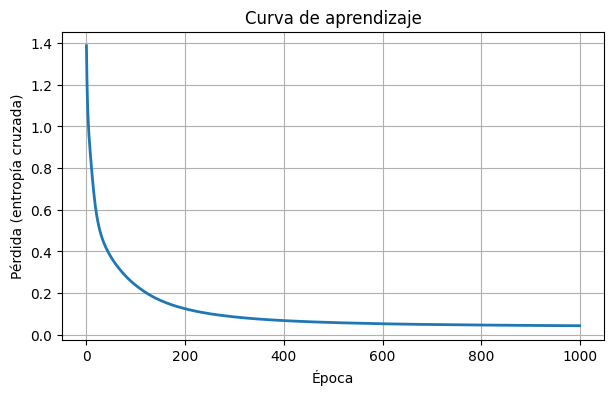

In [22]:
plt.figure(figsize=(7, 4))  # Crea una figura de 7x4 pulgadas
plt.plot(modelo.historial, lw=2)  # Grafica la pérdida en cada época
plt.xlabel("Época")  # Etiqueta del eje X
plt.ylabel("Pérdida (entropía cruzada)")  # Etiqueta del eje Y
plt.title("Curva de aprendizaje")  # Título del gráfico
plt.grid(True)  # Activa la cuadrícula
plt.show()  # Muestra el gráfico

## 4. Evaluación del modelo
- **Accuracy** = predicciones correctas / total de predicciones.
- **Matriz de confusión**: la fila es la clase real y la columna la predicha; la diagonal contiene los aciertos.

In [23]:
y_pred_train = modelo.predict(X_train_s)  # Predice las clases del conjunto de entrenamiento
y_pred_test = modelo.predict(X_test_s)  # Predice las clases del conjunto de prueba
acc_train = np.mean(y_pred_train == y_train)  # Accuracy en entrenamiento: proporción de aciertos
acc_test = np.mean(y_pred_test == y_test)  # Accuracy en prueba: proporción de aciertos
print(f"Accuracy entrenamiento: {acc_train:.4f}")  # Muestra el accuracy de entrenamiento
print(f"Accuracy prueba:        {acc_test:.4f}")  # Muestra el accuracy de prueba

Accuracy entrenamiento: 0.9810
Accuracy prueba:        1.0000


[[15  0  0]
 [ 0 15  0]
 [ 0  0 15]]


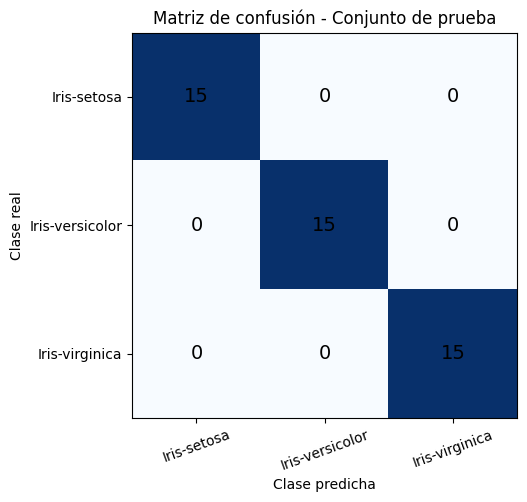

In [24]:
cm = np.zeros((K, K), dtype=int)  # Matriz de confusión K x K inicializada en ceros
np.add.at(cm, (y_test, y_pred_test), 1)  # Suma 1 en la celda (clase real, clase predicha) por cada muestra de prueba
print(cm)  # Imprime la matriz como arreglo numérico
plt.figure(figsize=(5.5, 5))  # Crea una figura de 5.5x5 pulgadas
plt.imshow(cm, cmap="Blues")  # Dibuja la matriz como mapa de color
for i in range(K):  # Recorre las filas (clase real)
    for j in range(K):  # Recorre las columnas (clase predicha)
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)  # Escribe el conteo en cada celda
plt.xticks(range(K), clases, rotation=20)  # Nombres de las clases en el eje X (predicho)
plt.yticks(range(K), clases)  # Nombres de las clases en el eje Y (real)
plt.xlabel("Clase predicha")  # Etiqueta del eje X
plt.ylabel("Clase real")  # Etiqueta del eje Y
plt.title("Matriz de confusión - Conjunto de prueba")  # Título del gráfico
plt.show()  # Muestra el gráfico